Select parameter combinations to use for simulations
  

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import os


### Let's look at the recovery time and R0 values for a variety of diseases that can be modelled with the SIR model

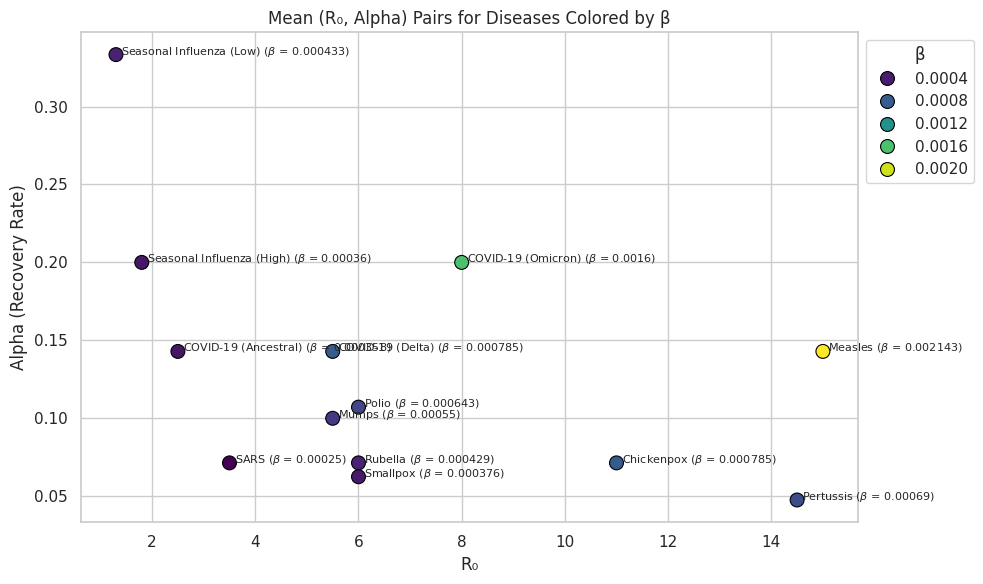

In [2]:
#List of common diseases and their ranges for recovery days and R0
disease_data = [
    {"Disease": "Seasonal Influenza (Low)", "RecoveryDays": (3,), "R0": (1.3,)},
    {"Disease": "Seasonal Influenza (High)", "RecoveryDays": (5,), "R0": (1.8,)},
    {"Disease": "COVID-19 (Ancestral)", "RecoveryDays": (7, 7), "R0": (2, 3)},
    {"Disease": "COVID-19 (Delta)", "RecoveryDays": (7, 7), "R0": (5, 6)},
    {"Disease": "COVID-19 (Omicron)", "RecoveryDays": (5, 5), "R0": (6, 10)},
    {"Disease": "SARS", "RecoveryDays": (14, 14), "R0": (2, 5)},
    {"Disease": "Measles", "RecoveryDays": (7, 7), "R0": (12, 18)},
    {"Disease": "Mumps", "RecoveryDays": (10, 10), "R0": (4, 7)},
    {"Disease": "Rubella", "RecoveryDays": (14, 14), "R0": (5, 7)},
    {"Disease": "Chickenpox", "RecoveryDays": (14, 14), "R0": (10, 12)},
    {"Disease": "Pertussis", "RecoveryDays": (21, 21), "R0": (12, 17)},
    {"Disease": "Smallpox", "RecoveryDays": (16, 16), "R0": (5, 7)},
    {"Disease": "Polio", "RecoveryDays": (7, 14), "R0": (5, 7)},
]

#Compute alpha and beta for each R0 and recovery time
N = 1000  # population size
rows = []
for d in disease_data:
    rec_days_range = d["RecoveryDays"]
    r0_range = d["R0"]
    for rec_days in rec_days_range:
        alpha = 1 / rec_days
        for r0 in r0_range:
            beta = (alpha * r0) / N
            rows.append({
                "Disease": d["Disease"],
                "RecoveryDays": rec_days,
                "Alpha": round(alpha, 4),
                "R0": r0,
                "Beta": round(beta, 6)
            })

df_diseases = pd.DataFrame(rows)

#Compute mean values per disease
df_mean = df_diseases.groupby("Disease").agg({
    "RecoveryDays": "mean",
    "Alpha": "mean",
    "R0": "mean",
    "Beta": "mean"
}).reset_index()

#Add labels with β value
df_mean["Label"] = df_mean.apply(lambda row: f"{row['Disease']} ($\\beta$ = {round(row['Beta'], 6)})", axis=1)

#Plot
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
scatter = sns.scatterplot(
    data=df_mean, x="R0", y="Alpha",
    hue="Beta", palette="viridis", s=100, edgecolor="black", legend="brief"
)

# Add text labels
for _, row in df_mean.iterrows():
    plt.text(row["R0"] + 0.1, row["Alpha"], row["Label"], fontsize=8)

# Final touches
plt.title("Mean (R₀, Alpha) Pairs for Diseases Colored by β")
plt.xlabel("R₀")
plt.ylabel("Alpha (Recovery Rate)")
plt.legend(title="β", loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


### Define an alpha vector to choose values from

In [3]:
alpha_values = [0.07, 0.1, 0.14, 0.2, 0.33]

alpha_recovery_table = pd.DataFrame({
    "Alpha": alpha_values,
    "Approx Recovery Time (days)": [round(1/a, 1) for a in alpha_values]
})

print("\nAlpha Recovery Time Table:")
print(alpha_recovery_table)


Alpha Recovery Time Table:
   Alpha  Approx Recovery Time (days)
0   0.07                         14.3
1   0.10                         10.0
2   0.14                          7.1
3   0.20                          5.0
4   0.33                          3.0


### Define beta vector based on range of R0 values to consider

In [4]:
#beta_values = [0.0002, 0.0004, 0.0006, 0.001, 0.002]
beta_values = [0.0004, 0.0008, 0.0012, 0.0016, 0.002]
N = 1000  # Population size

### Choose 20 combinations of $(\alpha, \beta)$ to test

In [5]:
all_combinations = list(itertools.product(alpha_values, beta_values))


combo_data = []
for alpha, beta in all_combinations:
    R0 = beta * N / alpha
    combo_data.append({
        "Alpha": alpha,
        "Beta": beta,
        "R0": R0
    })

combo_df = pd.DataFrame(combo_data)

# Filter to remove unrealistic R0 values (R0 < 1 or R0 > 15)
combo_df_filtered = combo_df[(combo_df["R0"] >= 1) & (combo_df["R0"] <= 15)].reset_index(drop=True)

# Identify the 3 highest R0 values for Alpha == 0.33 (if any exist in original filtered set)
highest_r0s = combo_df_filtered[combo_df_filtered["Alpha"] == 0.33].nlargest(3, "R0")

# Also remove Alpha = 0.2 and R0 = 10
to_remove = pd.concat([
    highest_r0s,
    combo_df_filtered[(combo_df_filtered["Alpha"] == 0.2) & (combo_df_filtered["R0"].round(4) == 10.0)]
])

# Remove specified points
combo_df_final = combo_df_filtered[~combo_df_filtered.index.isin(to_remove.index)].reset_index(drop=True)



combo_df['alpha_bin'] = pd.qcut(combo_df['Alpha'], q=4, duplicates='drop')
combo_df['r0_bin'] = pd.qcut(combo_df['R0'], q=5, duplicates='drop')

diverse_combos = combo_df.drop_duplicates(subset=['alpha_bin', 'r0_bin']).head(25)
selected_combos_df = diverse_combos[['Alpha', 'Beta', 'R0']].reset_index(drop=True)

In [6]:
combo_df_final

,Alpha,Beta,R0
0,0.07,0.0004,5.714286
1,0.07,0.0008,11.428571
2,0.10,0.0004,4.000000
3,0.10,0.0008,8.000000
4,0.10,0.0012,12.000000
5,0.14,0.0004,2.857143
6,0.14,0.0008,5.714286
7,0.14,0.0012,8.571429
8,0.14,0.0016,11.428571
9,0.14,0.0020,14.285714


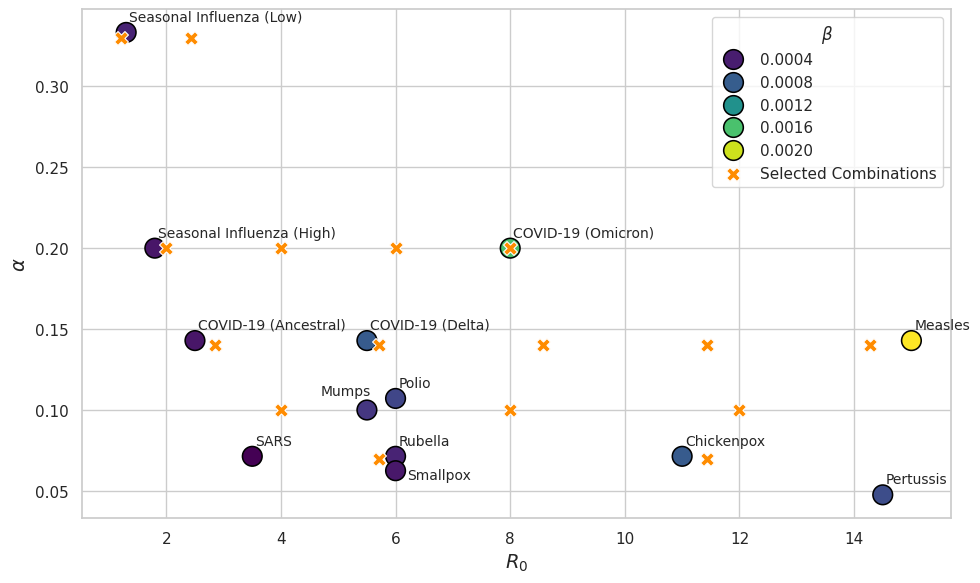


Selected 20 (Alpha, Beta, R0) combinations:
    Alpha    Beta         R0
0    0.07  0.0004   5.714286
1    0.07  0.0008  11.428571
2    0.10  0.0004   4.000000
3    0.10  0.0008   8.000000
4    0.10  0.0012  12.000000
5    0.14  0.0004   2.857143
6    0.14  0.0008   5.714286
7    0.14  0.0012   8.571429
8    0.14  0.0016  11.428571
9    0.14  0.0020  14.285714
10   0.20  0.0004   2.000000
11   0.20  0.0008   4.000000
12   0.20  0.0012   6.000000
13   0.20  0.0016   8.000000
14   0.33  0.0004   1.212121
15   0.33  0.0008   2.424242


In [7]:
disease_data = [
    {"Disease": "Seasonal Influenza (Low)", "RecoveryDays": (3,), "R0": (1.3,)},
    {"Disease": "Seasonal Influenza (High)", "RecoveryDays": (5,), "R0": (1.8,)},
    {"Disease": "COVID-19 (Ancestral)", "RecoveryDays": (7, 7), "R0": (2, 3)},
    {"Disease": "COVID-19 (Delta)", "RecoveryDays": (7, 7), "R0": (5, 6)},
    {"Disease": "COVID-19 (Omicron)", "RecoveryDays": (5, 5), "R0": (6, 10)},
    {"Disease": "SARS", "RecoveryDays": (14, 14), "R0": (2, 5)},
    {"Disease": "Measles", "RecoveryDays": (7, 7), "R0": (12, 18)},
    {"Disease": "Mumps", "RecoveryDays": (10, 10), "R0": (4, 7)},
    {"Disease": "Rubella", "RecoveryDays": (14, 14), "R0": (5, 7)},
    {"Disease": "Chickenpox", "RecoveryDays": (14, 14), "R0": (10, 12)},
    {"Disease": "Pertussis", "RecoveryDays": (21, 21), "R0": (12, 17)},
    {"Disease": "Smallpox", "RecoveryDays": (16, 16), "R0": (5, 7)},
    {"Disease": "Polio", "RecoveryDays": (7, 14), "R0": (5, 7)},
]

#Compute alpha and beta for each R0 and recovery time
N = 1000  # population size
rows = []
for d in disease_data:
    rec_days_range = d["RecoveryDays"]
    r0_range = d["R0"]
    for rec_days in rec_days_range:
        alpha = 1 / rec_days
        for r0 in r0_range:
            beta = (alpha * r0) / N
            rows.append({
                "Disease": d["Disease"],
                "RecoveryDays": rec_days,
                "Alpha": round(alpha, 4),
                "R0": r0,
                "Beta": round(beta, 6)
            })

df_diseases = pd.DataFrame(rows)

#Compute mean values per disease
df_mean = df_diseases.groupby("Disease").agg({
    "RecoveryDays": "mean",
    "Alpha": "mean",
    "R0": "mean",
    "Beta": "mean"
}).reset_index()

#Add labels with β value
df_mean["Label"] = df_mean.apply(lambda row: f"{row['Disease']}", axis=1)

#Directory for saving
# save_dir = '../data'
# save_path = os.path.join(save_dir, 'disease_scatter_custom_labels.png')

#Plot
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
scatter = sns.scatterplot(
    data=df_mean, x="R0", y="Alpha",
    hue="Beta", palette="viridis", s=200, edgecolor="black", legend="brief"
)
#sns.scatterplot(data=selected_combos_df, x="R0", y="Alpha", s=100, marker="X", color="darkorange", label="Selected Combos")
sns.scatterplot(data=combo_df_final , x="R0", y="Alpha", s=100, marker="X", color="darkorange", label="Selected Combinations")

# Define custom label offsets
offsets = {
    "Mumps": (-0.8, 0.009),       # top left
    "Smallpox": (0.2, -0.005),    # bottom right
}

# Add text labels with custom offset for specific diseases
for _, row in df_mean.iterrows():
    dx, dy = offsets.get(row["Disease"], (0.05, 0.007))  # default offset
    plt.text(row["R0"] + dx, row["Alpha"] + dy, row["Label"], fontsize=10)

plt.xlabel(r"$R_0$")


#plt.title(r"Selected (R₀, $\alpha$) Pairs")
plt.xlabel(r"$R_0$", fontsize = 14)
plt.ylabel(r"$\alpha$",  fontsize = 14)
plt.legend(title=r"$\beta$")
plt.grid(True)
plt.tight_layout()
# Save the figure
#plt.savefig(save_path, dpi=300)
plt.show()


print("\nSelected 20 (Alpha, Beta, R0) combinations:")
print(combo_df_final)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
#save params pairs
import csv


# Save combo_df_final to CSV for use in other scripts
combo_df_final.to_csv('../data/params_combos_regenerated.csv', index=False)